# MAT322 Group 3: Monte Carlo simulation and sensitivity analysis (Section 9)

Five properties: Bantry Bay, Observatory, Khayelitsha, Bellville and Brackenfell.

The question: if one household buys now with a deposit and a mortgage, and another invests the deposit and then puts the mortgage-equivalent instalment into the same investment every month, how often does the investing household end up with more wealth? Investment returns are random, so we simulate many possible futures.

Run the cells from top to bottom. The whole notebook takes a few minutes.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.options.display.float_format = '{:,.2f}'.format

The assumptions all sit in one cell so they are easy to change. `SIGMA = 0.1461` comes from the monthly STX40 price history (standard deviation of monthly log returns 0.0422, times the square root of 12). `R = 0.1238` is the ten-year annualised return in the Satrix fact sheet.

In [2]:
SEED   = 2026       # same seed everywhere, so every scenario sees the same random shocks
NPATH  = 10_000     # number of simulated futures
STEPS  = 240        # 20 years of monthly steps
YEARS  = (10, 15, 20)

R      = 0.1238     # compound investment return per year
SIGMA  = 0.1461     # annual volatility of the investment
INF    = 0.052      # inflation, only used for the real-terms results
RM     = 0.1075     # mortgage rate
G      = 0.08       # property growth per year (same for all five properties)

# name: (purchase price, deposit)
PROPS = {
    "Bantry Bay":  (10_000_000, 3_000_000),
    "Observatory": ( 3_500_000, 1_500_000),
    "Khayelitsha": (   500_000,    90_000),
    "Bellville":   ( 2_000_000,   600_000),
    "Brackenfell": ( 1_500_000,   450_000),
}

## 2. Mortgage and investment formulas

`pay` is the standard level-payment formula for the monthly instalment, and `bal` gives what is still owed after `k` payments. `det_wealth` is the closed-form value of the investing household when there is no randomness: the deposit grows at `r`, and each monthly instalment is invested at the end of the month at the equivalent monthly rate. We use it as a check on the simulation and for the break-even returns.

In [3]:
def pay(L, rate=RM, N=240):
    i = rate / 12
    return L * i / (1 - (1 + i) ** -N)

def bal(L, M, k, rate=RM):
    i = rate / 12
    return L * (1 + i) ** k - M * ((1 + i) ** k - 1) / i

def det_wealth(D, M, n, r=R):
    j = (1 + r) ** (1 / 12) - 1
    return D * (1 + r) ** n + M * ((1 + j) ** (12 * n) - 1) / j

def break_even(D, M, target, n):
    # the constant return at which the investing household reaches `target` after n years
    return brentq(lambda r: det_wealth(D, M, n, r) - target, -0.5, 1.0)

## 3. The simulation

Each month the investment is multiplied by a random growth factor and then the instalment `M` is added:

$$V_{k+1} = V_k \exp\!\Big(\tfrac{\ln(1+r)}{12} + \tfrac{\sigma}{\sqrt{12}}\,Z_k\Big) + M, \qquad Z_k \sim N(0,1),\quad V_0 = D$$

`draws` creates the table of random shocks `Z` (one row per simulated future, one column per month). We create it once and reuse it everywhere, so differences between scenarios are not just random noise.

One thing to be aware of: there is no $-\sigma^2/2$ correction, so `R` behaves like the growth of the *median* path. The average path grows a little faster.

In [4]:
def draws(seed=SEED):
    return np.random.default_rng(seed).standard_normal((NPATH, STEPS))

def simulate(D, M, Z, r=R, sigma=SIGMA, keep_all=False):
    # returns wealth at 10, 15 and 20 years for every path
    # (and the whole monthly history if keep_all=True)
    V = np.full(Z.shape[0], float(D))
    drift = np.log(1 + r) / 12
    shock = sigma / np.sqrt(12)
    at_year, history = {}, []
    for k in range(STEPS):
        V = V * np.exp(drift + shock * Z[:, k]) + M
        if keep_all:
            history.append(V.copy())
        if (k + 1) in (120, 180, 240):
            at_year[(k + 1) // 12] = V.copy()
    return (at_year, np.array(history)) if keep_all else at_year

`outcome_probs` runs one scenario and returns the two probabilities we report for each horizon:

* **exceeds**: the investing household's wealth is higher than the buyer's equity (house value minus the mortgage still owed).
* **funds**: the investing household's wealth is enough to pay for the projected house outright.

The mortgage rate and property growth are arguments so the same function serves the sensitivity tables later.

In [5]:
def outcome_probs(P, D, Z, g=G, rate=RM, r=R, sigma=SIGMA):
    L = P - D
    M = pay(L, rate)
    wealth = simulate(D, M, Z, r, sigma)
    out = {}
    for y in YEARS:
        house  = P * (1 + g) ** y
        equity = house - bal(L, M, 12 * y, rate)
        out[y] = {"exceeds": (wealth[y] > equity).mean(),
                  "funds":   (wealth[y] >= house).mean()}
    return out

## 4. Checking the code before trusting it

Two checks. First, with `sigma = 0` there is no randomness, so the simulation must match the closed-form wealth exactly. Second, running Observatory with the old 16% volatility should give the figures from the previous draft of Section 9 (10-year mean R10,400,637, median R9,511,299).

In [6]:
Z = draws()

# check 1: no randomness -> must equal the closed-form answer
for name, (P, D) in PROPS.items():
    M = pay(P - D)
    sim = simulate(D, M, Z[:1], sigma=0.0)
    gap = max(abs(sim[y][0] - det_wealth(D, M, y)) for y in YEARS)
    print(f"{name:12s} largest gap vs closed form: R{gap:.6f}")

# check 2: Observatory at 16% volatility vs the previous draft
P, D = PROPS["Observatory"]
old = simulate(D, pay(P - D), Z, sigma=0.16)[10]
print(f"\nObservatory, 16% vol, 10 years: mean {old.mean():,.0f}, median {np.median(old):,.0f}")

Bantry Bay   largest gap vs closed form: R0.000001
Observatory  largest gap vs closed form: R0.000000
Khayelitsha  largest gap vs closed form: R0.000000
Bellville    largest gap vs closed form: R0.000000
Brackenfell  largest gap vs closed form: R0.000000

Observatory, 16% vol, 10 years: mean 10,400,637, median 9,511,299


## 5. Base case for all five properties

For each property we record the deterministic benchmarks (house price, mortgage balance, equity, break-even returns) and the simulated distribution of the investing household's wealth. `ratio_q` stores wealth divided by equity, which is what Figure 4 plots. The monthly percentiles are kept for the fan charts.

In [7]:
base, paths = {}, {}
for name, (P, D) in PROPS.items():
    L = P - D
    M = pay(L)
    wealth, history = simulate(D, M, Z, keep_all=True)
    res = {"price": P, "deposit": D, "loan": L, "M": M}
    for y in YEARS:
        house  = P * (1 + G) ** y
        bal_y  = bal(L, M, 12 * y)
        equity = house - bal_y
        w      = wealth[y]
        f      = (1 + INF) ** y
        res[y] = dict(house=house, balance=bal_y, equity=equity,
                      det=det_wealth(D, M, y),
                      mean=w.mean(), median=np.median(w),
                      p5=np.percentile(w, 5), p95=np.percentile(w, 95),
                      p_exceeds=(w > equity).mean(), p_funds=(w >= house).mean(),
                      real_equity=equity / f, real_median=np.median(w) / f,
                      real_p5=np.percentile(w, 5) / f,
                      be_equity=break_even(D, M, equity, y),
                      be_house=break_even(D, M, house, y),
                      ratio_q=np.percentile(w / equity, [5, 25, 50, 75, 95]))
    # lump sum alone: same simulation but with no monthly contributions
    lump = simulate(D, 0.0, Z)
    for y in YEARS:
        res[y]["p_lump"] = (lump[y] >= P * (1 + G) ** y).mean()
    base[name] = res
    paths[name] = (history, L, M, P)

Inputs and instalments (Table 13).

In [8]:
pd.DataFrame({n: {"Price": b["price"], "Deposit": b["deposit"],
                  "Deposit %": 100 * b["deposit"] / b["price"],
                  "Mortgage": b["loan"], "Instalment M": b["M"]}
              for n, b in base.items()}).T

,Price,Deposit,Deposit %,Mortgage,Instalment M
Bantry Bay,"10,000,000.00","3,000,000.00",30.00,"7,000,000.00","71,066.03"
Observatory,"3,500,000.00","1,500,000.00",42.86,"2,000,000.00","20,304.58"
Khayelitsha,"500,000.00","90,000.00",18.00,"410,000.00","4,162.44"
Bellville,"2,000,000.00","600,000.00",30.00,"1,400,000.00","14,213.21"
Brackenfell,"1,500,000.00","450,000.00",30.00,"1,050,000.00","10,659.90"


Distribution of the investing household's wealth next to the buyer's equity (Tables 15 and 16).

In [9]:
rows = []
for n, b in base.items():
    for y in YEARS:
        x = b[y]
        rows.append([n, y, x["house"], x["balance"], x["equity"], x["det"],
                     x["mean"], x["median"], x["p5"], x["p95"]])
pd.DataFrame(rows, columns=["Property", "Years", "House price", "Mortgage balance",
                            "Buy-now equity", "Wealth (no randomness)",
                            "Mean", "Median", "5th pct", "95th pct"]
            ).set_index(["Property", "Years"]).round(0)

House price  Mortgage balance  Buy-now equity  \
Property    Years                                                   
Bantry Bay  10    21,589,250.00      5,212,463.00   16,376,787.00   
            15    31,721,691.00      3,287,361.00   28,434,330.00   
            20    46,609,571.00              0.00   46,609,571.00   
Observatory 10     7,556,237.00      1,489,275.00    6,066,962.00   
            15    11,102,592.00        939,246.00   10,163,346.00   
            20    16,313,350.00              0.00   16,313,350.00   
Khayelitsha 10     1,079,462.00        305,301.00      774,161.00   
            15     1,586,085.00        192,545.00    1,393,539.00   
            20     2,330,479.00              0.00    2,330,479.00   
Bellville   10     4,317,850.00      1,042,493.00    3,275,357.00   
            15     6,344,338.00        657,472.00    5,686,866.00   
            20     9,321,914.00              0.00    9,321,914.00   
Brackenfell 10     3,238,387.00        781,869.00    2,456,518.00   
            15     4,758,254.00        493,104.00    4,265,149.00   
            20     6,991,436.00              0.00    6,991,436.00   

                   Wealth (no randomness)           Mean         Median  \
Property    Years                                                         
Bantry Bay  10              25,728,382.00  27,794,608.00  25,976,879.00   
            15              51,878,557.00  58,481,318.00  52,363,349.00   
            20              98,751,233.00 116,925,763.00 100,521,079.00   
Observatory 10               9,416,369.00  10,227,284.00   9,495,050.00   
            15              18,524,560.00  21,030,023.00  18,623,285.00   
            20              34,850,465.00  41,605,184.00  35,356,594.00   
Khayelitsha 10               1,231,561.00   1,323,174.00   1,243,766.00   
            15               2,544,986.00   2,849,191.00   2,567,131.00   
            20               4,899,224.00   5,755,466.00   4,997,094.00   
Bellville   10               5,145,676.00   5,558,922.00   5,195,376.00   
            15              10,375,711.00  11,696,264.00  10,472,670.00   
            20              19,750,247.00  23,385,153.00  20,104,216.00   
Brackenfell 10               3,859,257.00   4,169,191.00   3,896,532.00   
            15               7,781,784.00   8,772,198.00   7,854,502.00   
            20              14,812,685.00  17,538,864.00  15,078,162.00   

                        5th pct       95th pct  
Property    Years                               
Bantry Bay  10    14,732,847.00  47,233,018.00  
            15    26,166,805.00 110,332,630.00  
            20    43,776,269.00 243,081,234.00  
Observatory 10     5,219,904.00  17,927,435.00  
            15     9,019,506.00  40,471,893.00  
            20    14,908,955.00  88,891,786.00  
Khayelitsha 10       731,654.00   2,190,457.00  
            15     1,324,963.00   5,258,379.00  
            20     2,244,472.00  11,748,706.00  
Bellville   10     2,946,569.00   9,446,604.00  
            15     5,233,361.00  22,066,526.00  
            20     8,755,254.00  48,616,247.00  
Brackenfell 10     2,209,927.00   7,084,953.00  
            15     3,925,021.00  16,549,895.00  
            20     6,566,440.00  36,462,185.00

Base-case probabilities (Tables 17 and 18). Bantry Bay, Bellville and Brackenfell all put down 30%, so their rows come out identical: everything in the model scales with the price, so only the deposit-to-price ratio changes the probabilities.

In [10]:
rows = []
for n, b in base.items():
    rows.append([n] + [100 * b[y]["p_exceeds"] for y in YEARS]
                    + [100 * b[y]["p_funds"] for y in YEARS]
                    + [100 * b[y]["p_lump"] for y in YEARS])
cols = pd.MultiIndex.from_tuples(
    [("Exceeds equity (%)", f"{y}y") for y in YEARS] +
    [("Funds the house (%)", f"{y}y") for y in YEARS] +
    [("Lump sum alone funds house (%)", f"{y}y") for y in YEARS])
pd.DataFrame([r[1:] for r in rows], index=[r[0] for r in rows], columns=cols).round(1)

Exceeds equity (%)             Funds the house (%)              \
                           10y   15y   20y                 10y   15y   20y   
Bantry Bay               90.90 92.80 93.70               69.90 88.30 93.70   
Observatory              88.80 91.60 93.00               72.80 87.80 93.00   
Khayelitsha              92.70 93.80 94.10               66.60 88.50 94.10   
Bellville                90.90 92.80 93.70               69.90 88.30 93.70   
Brackenfell              90.90 92.80 93.70               69.90 88.30 93.70   

            Lump sum alone funds house (%)              
                                       10y   15y   20y  
Bantry Bay                            4.00 14.10 27.00  
Observatory                          15.90 32.80 46.80  
Khayelitsha                           0.20  2.20  7.80  
Bellville                             4.00 14.10 27.00  
Brackenfell                           4.00 14.10 27.00

Break-even returns (Table 23): the constant return the investing household would need to just match the buyer's equity, or to just pay for the whole house.

In [11]:
rows = []
for n, b in base.items():
    rows.append([100 * b[y]["be_equity"] for y in YEARS] + [100 * b[y]["be_house"] for y in YEARS])
cols = pd.MultiIndex.from_tuples([("Matches equity (%)", f"{y}y") for y in YEARS] +
                                 [("Funds the house (%)", f"{y}y") for y in YEARS])
pd.DataFrame(rows, index=list(base), columns=cols).round(2)

Matches equity (%)           Funds the house (%)          
                           10y  15y  20y                 10y  15y  20y
Bantry Bay                5.50 6.32 6.83                9.72 7.44 6.83
Observatory               6.19 6.73 7.09                9.29 7.57 7.09
Khayelitsha               4.68 5.87 6.56               10.22 7.30 6.56
Bellville                 5.50 6.32 6.83                9.72 7.44 6.83
Brackenfell               5.50 6.32 6.83                9.72 7.44 6.83

Inflation-adjusted values in today's rand (Table 24).

In [12]:
rows = []
for n, b in base.items():
    for y in YEARS:
        rows.append([n, y, b[y]["real_equity"], b[y]["real_median"], b[y]["real_p5"]])
pd.DataFrame(rows, columns=["Property", "Years", "Buy-now equity", "Investing: median",
                            "Investing: 5th pct"]).set_index(["Property", "Years"]).round(0)

Buy-now equity  Investing: median  Investing: 5th pct
Property    Years                                                       
Bantry Bay  10       9,864,415.00      15,646,946.00        8,874,202.00
            15      13,292,507.00      24,478,867.00       12,232,482.00
            20      16,910,650.00      36,470,553.00       15,882,686.00
Observatory 10       3,654,382.00       5,719,260.00        3,144,163.00
            15       4,751,170.00       8,706,031.00        4,216,447.00
            20       5,918,728.00      12,827,902.00        5,409,192.00
Khayelitsha 10         466,309.00         749,172.00          440,705.00
            15         651,453.00       1,200,085.00          619,395.00
            20         845,533.00       1,813,021.00          814,328.00
Bellville   10       1,972,883.00       3,129,389.00        1,774,840.00
            15       2,658,501.00       4,895,773.00        2,446,496.00
            20       3,382,130.00       7,294,111.00        3,176,537.00
Brackenfell 10       1,479,662.00       2,347,042.00        1,331,130.00
            15       1,993,876.00       3,671,830.00        1,834,872.00
            20       2,536,598.00       5,470,583.00        2,382,403.00

## 6. Sensitivity analysis

We change one assumption at a time and rerun. Because `Z` is reused, a change in the result comes from the assumption and not from new random numbers.

**Return and volatility** (Tables 19 and 20, Figure 5).

In [13]:
RETURNS = [0.06, 0.08, 0.10, 0.12, 0.1238, 0.14]
VOLS    = [0.10, 0.1461, 0.18, 0.22]

grid = {}
for name, (P, D) in PROPS.items():
    for r in RETURNS:
        for s in VOLS:
            grid[(name, r, s)] = outcome_probs(P, D, Z, r=r, sigma=s)

def grid_table(name, y):
    t = pd.DataFrame({f"{100*r:g}%": [100 * grid[(name, r, s)][y]["exceeds"] for s in VOLS]
                      for r in RETURNS}, index=[f"vol {100*s:g}%" for s in VOLS])
    return t.round(1)

grid_table("Observatory", 10)

,6%,8%,10%,12%,12.38%,14%
vol 10%,48.50,70.10,86.60,95.10,96.30,98.70
vol 14.61%,49.60,65.00,77.70,87.30,88.80,93.50
vol 18%,50.10,62.60,73.40,82.70,84.20,89.40
vol 22%,50.70,60.90,69.90,78.20,79.60,85.00


Change the property name or the horizon in the last line above to see the other grids. The table for the base volatility across all five properties:

In [14]:
pd.DataFrame({f"{y}y: {100*r:g}%": [100 * grid[(n, r, SIGMA)][y]["exceeds"] for n in PROPS]
              for y in (10, 20) for r in RETURNS}, index=list(PROPS)).round(1)

,10y: 6%,10y: 8%,10y: 10%,10y: 12%,10y: 12.38%,10y: 14%,20y: 6%,20y: 8%,20y: 10%,20y: 12%,20y: 12.38%,20y: 14%
Bantry Bay,55.20,69.60,81.60,89.80,90.90,94.80,42.90,64.40,82.10,92.40,93.70,97.30
Observatory,49.60,65.00,77.70,87.30,88.80,93.50,39.80,61.60,80.20,91.60,93.00,97.00
Khayelitsha,61.50,74.60,85.10,91.70,92.70,96.10,46.10,66.90,83.50,93.20,94.10,97.50
Bellville,55.20,69.60,81.60,89.80,90.90,94.80,42.90,64.40,82.10,92.40,93.70,97.30
Brackenfell,55.20,69.60,81.60,89.80,90.90,94.80,42.90,64.40,82.10,92.40,93.70,97.30


**Property growth** (Table 21) and **mortgage rate** (Table 22). With a different mortgage rate both the instalment and the balance change, and the investing household invests the new, larger or smaller instalment.

In [15]:
growth_rates = [0.08, 0.09, 0.10, 0.11]
mort_rates   = [0.0975, 0.1025, 0.1075, 0.1125, 0.1175]

growth_res = {n: {g: outcome_probs(P, D, Z, g=g) for g in growth_rates} for n, (P, D) in PROPS.items()}
rate_res   = {n: {m: outcome_probs(P, D, Z, rate=m) for m in mort_rates} for n, (P, D) in PROPS.items()}

print("Probability of exceeding buy-now equity (%), by property growth")
display(pd.DataFrame({f"{y}y @ {100*g:g}%": [100 * growth_res[n][g][y]["exceeds"] for n in PROPS]
                      for y in (10, 20) for g in growth_rates}, index=list(PROPS)).round(1))

print("Probability of exceeding buy-now equity (%), by mortgage rate")
display(pd.DataFrame({f"{y}y @ {100*m:.2f}%": [100 * rate_res[n][m][y]["exceeds"] for n in PROPS]
                      for y in (10, 20) for m in mort_rates}, index=list(PROPS)).round(1))

Probability of exceeding buy-now equity (%), by property growth


,10y @ 8%,10y @ 9%,10y @ 10%,10y @ 11%,20y @ 8%,20y @ 9%,20y @ 10%,20y @ 11%
Bantry Bay,90.90,83.80,73.80,63.00,93.70,87.70,78.50,66.60
Observatory,88.80,81.70,72.40,62.20,93.00,87.00,78.00,66.20
Khayelitsha,92.70,85.80,75.30,63.30,94.10,88.30,79.10,66.70
Bellville,90.90,83.80,73.80,63.00,93.70,87.70,78.50,66.60
Brackenfell,90.90,83.80,73.80,63.00,93.70,87.70,78.50,66.60


Probability of exceeding buy-now equity (%), by mortgage rate


,10y @ 9.75%,10y @ 10.25%,10y @ 10.75%,10y @ 11.25%,10y @ 11.75%,20y @ 9.75%,20y @ 10.25%,20y @ 10.75%,20y @ 11.25%,20y @ 11.75%
Bantry Bay,88.10,89.60,90.90,92.10,93.10,92.40,93.10,93.70,94.20,94.70
Observatory,86.60,87.60,88.80,90.00,91.00,91.90,92.40,93.00,93.60,94.00
Khayelitsha,89.90,91.30,92.70,94.20,95.20,92.80,93.50,94.10,94.70,95.30
Bellville,88.10,89.60,90.90,92.10,93.10,92.40,93.10,93.70,94.20,94.70
Brackenfell,88.10,89.60,90.90,92.10,93.10,92.40,93.10,93.70,94.20,94.70


## 7. Is the Monte Carlo noise small enough?

We repeat the base case with eight different seeds (the report's 2026 plus seeds 1 to 7) and look at how far apart the highest and lowest estimates are. For 10,000 paths the standard error of a probability is at most 0.5 percentage points, so gaps of about one point should not be over-interpreted.

In [16]:
seeds = [2026, 1, 2, 3, 4, 5, 6, 7]
spread = {}
for name, (P, D) in PROPS.items():
    runs = [outcome_probs(P, D, draws(s)) for s in seeds]
    spread[name] = {f"{y}y": 100 * (max(r[y]["exceeds"] for r in runs) -
                                    min(r[y]["exceeds"] for r in runs)) for y in YEARS}
pd.DataFrame(spread).T.round(2).rename_axis("Spread in percentage points")

,10y,15y,20y
Spread in percentage points,,,
Bantry Bay,0.62,0.80,0.91
Observatory,0.72,0.76,1.02
Khayelitsha,0.81,0.91,0.98
Bellville,0.62,0.80,0.91
Brackenfell,0.62,0.80,0.91


## 8. Figures

**Figure 3.** For each property, the range of simulated wealth over time (shaded bands show the middle 50% and middle 90% of paths, on a log scale) against the buyer's equity and the house price. The last panel shows how the probability of beating the buyer's equity builds up over the 20 years.

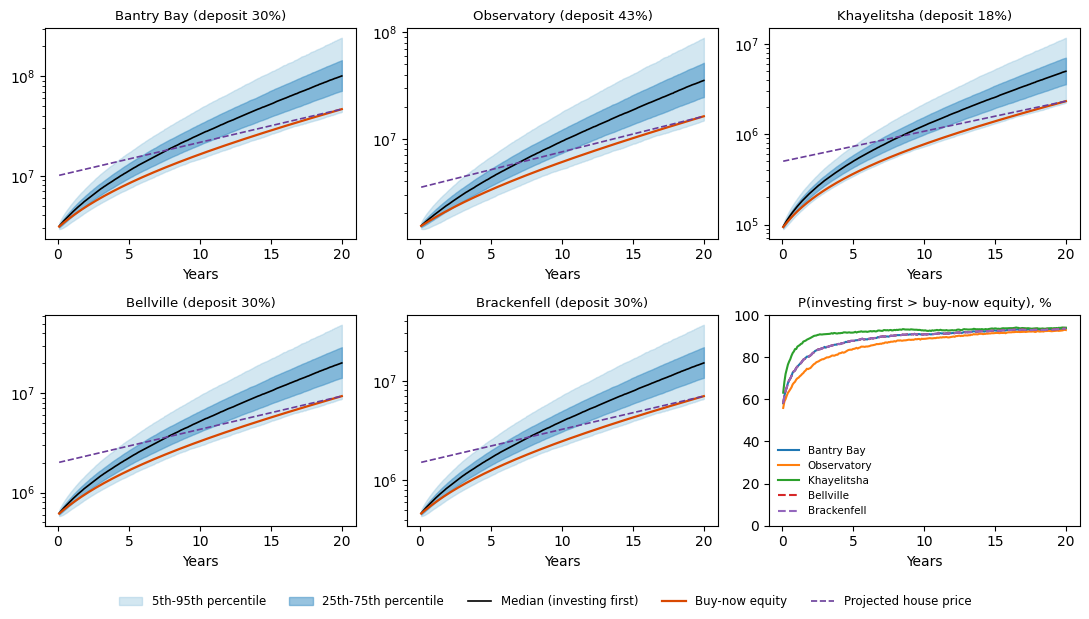

In [17]:
t = np.arange(1, 241) / 12
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))

for ax, (name, (history, L, M, P)) in zip(axes.flat, paths.items()):
    p5, p25, p50, p75, p95 = np.percentile(history, [5, 25, 50, 75, 95], axis=1)
    k = np.arange(1, 241)
    house = P * (1 + G) ** (k / 12)
    equity = house - np.array([bal(L, M, j) for j in k])
    ax.fill_between(t, p5, p95, color="#9ecae1", alpha=.45, label="5th-95th percentile")
    ax.fill_between(t, p25, p75, color="#4292c6", alpha=.55, label="25th-75th percentile")
    ax.plot(t, p50, "k", lw=1.2, label="Median (investing first)")
    ax.plot(t, equity, color="#d94801", lw=1.6, label="Buy-now equity")
    ax.plot(t, house, color="#6a3d9a", ls="--", lw=1.2, label="Projected house price")
    ax.set_yscale("log")
    ax.set_title(f"{name} (deposit {100*base[name]['deposit']/P:.0f}%)", fontsize=9.5)
    ax.set_xlabel("Years")
    p_t = (history > equity[:, None]).mean(axis=1) * 100
    axes.flat[5].plot(t, p_t, label=name, ls="--" if name in ("Bellville", "Brackenfell") else "-")

axes.flat[5].set_ylim(0, 100)
axes.flat[5].set_title("P(investing first > buy-now equity), %", fontsize=9.5)
axes.flat[5].set_xlabel("Years")
axes.flat[5].legend(fontsize=7.5, frameon=False)
h, l = axes.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, frameon=False, fontsize=8.5)
fig.tight_layout(rect=(0, .05, 1, 1))
plt.show()

**Figure 4.** Wealth of the investing household as a multiple of the buyer's equity. Anything below the line at 1 means the investing household ended up behind.

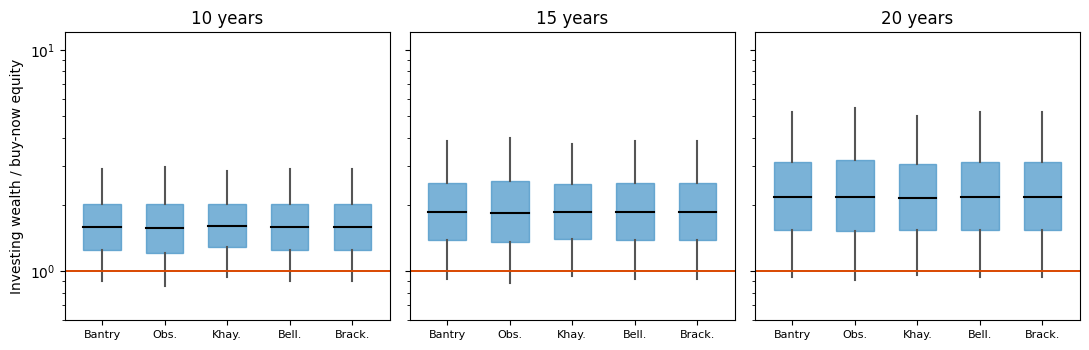

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
labels = ["Bantry", "Obs.", "Khay.", "Bell.", "Brack."]
for ax, y in zip(axes, YEARS):
    for i, name in enumerate(PROPS):
        q5, q25, q50, q75, q95 = base[name][y]["ratio_q"]
        ax.add_patch(plt.Rectangle((i - .3, q25), .6, q75 - q25, color="#4292c6", alpha=.7))
        ax.plot([i - .3, i + .3], [q50, q50], "k")
        ax.plot([i, i], [q5, q25], color="#555")
        ax.plot([i, i], [q75, q95], color="#555")
    ax.axhline(1, color="#d94801", lw=1.4)
    ax.set_yscale("log"); ax.set_xlim(-.6, 4.6); ax.set_ylim(.6, 12)
    ax.set_xticks(range(5)); ax.set_xticklabels(labels, fontsize=8)
    ax.set_title(f"{y} years")
axes[0].set_ylabel("Investing wealth / buy-now equity")
fig.tight_layout()
plt.show()

**Figure 5.** Return-by-volatility heatmaps. Only three deposit ratios exist among the five properties, so we draw Khayelitsha (18%), Bellville (standing in for the three 30% properties) and Observatory (43%).

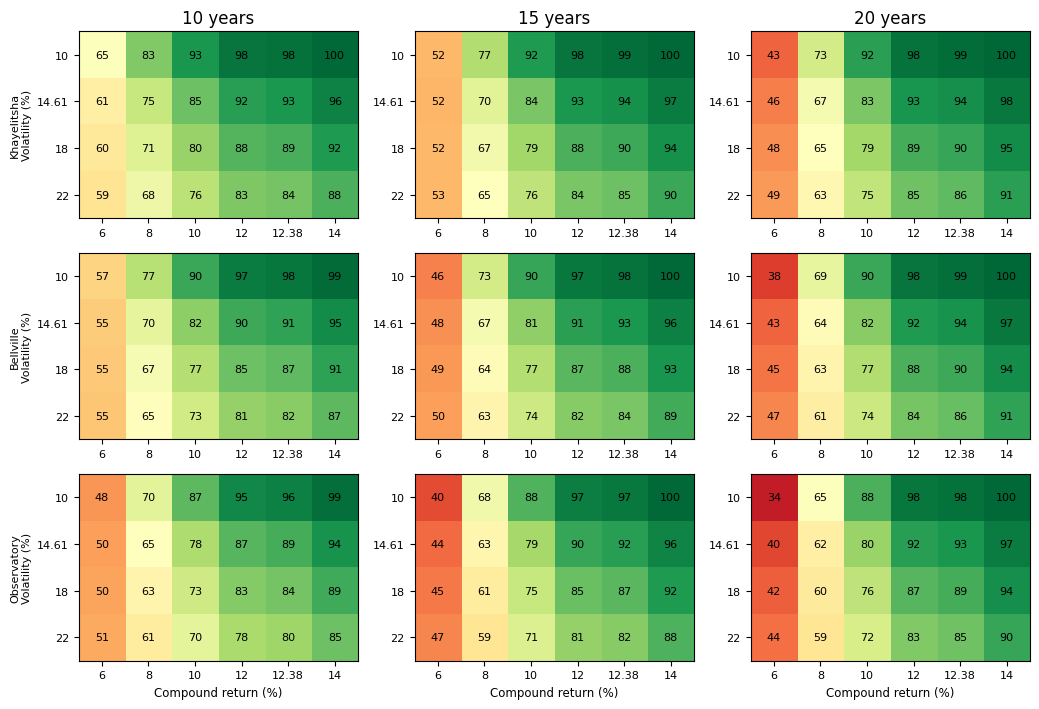

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(10.5, 7.2))
for i, name in enumerate(["Khayelitsha", "Bellville", "Observatory"]):
    for j, y in enumerate(YEARS):
        M_ = np.array([[100 * grid[(name, r, s)][y]["exceeds"] for r in RETURNS] for s in VOLS])
        ax = axes[i, j]
        ax.imshow(M_, cmap="RdYlGn", vmin=30, vmax=100, aspect="auto")
        for u in range(len(VOLS)):
            for v in range(len(RETURNS)):
                ax.text(v, u, f"{M_[u, v]:.0f}", ha="center", va="center", fontsize=8)
        ax.set_xticks(range(len(RETURNS))); ax.set_xticklabels(["6", "8", "10", "12", "12.38", "14"], fontsize=8)
        ax.set_yticks(range(len(VOLS))); ax.set_yticklabels(["10", "14.61", "18", "22"], fontsize=8)
        if i == 0: ax.set_title(f"{y} years")
        if j == 0: ax.set_ylabel(f"{name}\nVolatility (%)", fontsize=8)
        if i == 2: ax.set_xlabel("Compound return (%)", fontsize=8.5)
fig.tight_layout()
plt.show()

**Figure 6.** How the probability falls as property growth rises.

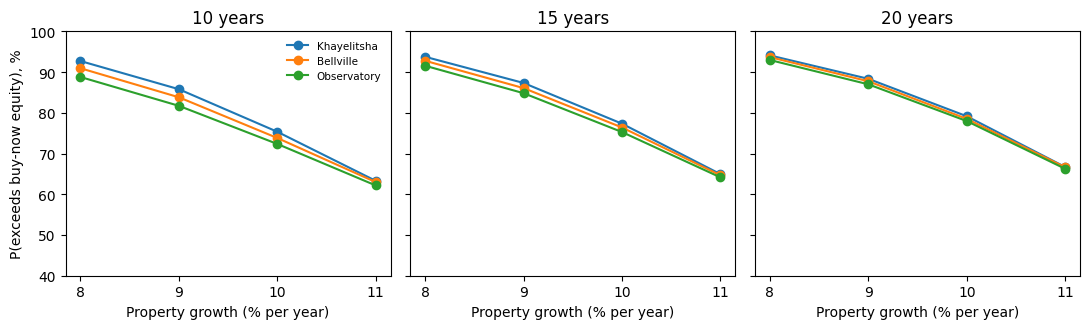

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, y in zip(axes, YEARS):
    for name in ["Khayelitsha", "Bellville", "Observatory"]:
        ax.plot([100 * g for g in growth_rates],
                [100 * growth_res[name][g][y]["exceeds"] for g in growth_rates], marker="o", label=name)
    ax.set_title(f"{y} years"); ax.set_xlabel("Property growth (% per year)")
    ax.set_xticks([8, 9, 10, 11]); ax.set_ylim(40, 100)
axes[0].set_ylabel("P(exceeds buy-now equity), %")
axes[0].legend(fontsize=7.5, frameon=False)
fig.tight_layout()
plt.show()